# Top 15 Minor GL Numbers by FY Revenue Share

This notebook reads the combined DAWN revenue CSV, keeps only rows where `Type` is `Minor`, groups by `GL Number` and `fy`, and creates a top-15 table by fiscal-year revenue share. It uses only built-in Python libraries, so it does not require pandas.

In [3]:
from collections import defaultdict
from html import escape
from pathlib import Path
import csv

try:
    from IPython.display import HTML, display
except ImportError:
    HTML = None
    display = print

In [4]:
file_name = "dawn_revenue_accounts_combined_history.csv"
search_roots = [Path.cwd(), *Path.cwd().parents]
candidate_paths = []

for root in search_roots:
    candidate_paths.extend([root / "data" / file_name, root / file_name])

csv_path = next((path for path in candidate_paths if path.exists()), None)

if csv_path is None:
    searched = "\n".join(str(path) for path in candidate_paths)
    raise FileNotFoundError(f"Could not find {file_name}. Searched:\n{searched}")

csv_path

WindowsPath('c:/Users/Syed.Uddin/OneDrive - State of Nevada/DAWN_DATA/dawn_Data/data/dawn_revenue_accounts_combined_history.csv')

In [5]:
def amount_value(row):
    try:
        return float(str(row.get("Amount", "0")).replace(",", ""))
    except ValueError:
        return 0.0


with csv_path.open("r", newline="", encoding="utf-8-sig") as f:
    df = list(csv.DictReader(f))

for row in df:
    row["Amount"] = amount_value(row)

len(df), df[:3]

(332178,
 [{'Doc Number': 'CR 010 00008235185',
   'Date': '2019-07-29',
   'Amount': 200.0,
   'level_1_id': '25842',
   'level_2_id': '70021',
   'GL Number': '3102',
   'description': 'ATHLETIC COMM GATE/TV FEES',
   'Type': 'Minor',
   'BA Number': '9010',
   'fy': '2020'},
  {'Doc Number': 'CR 010 00008235187',
   'Date': '2019-07-30',
   'Amount': 10724.0,
   'level_1_id': '25842',
   'level_2_id': '70021',
   'GL Number': '3102',
   'description': 'ATHLETIC COMM GATE/TV FEES',
   'Type': 'Minor',
   'BA Number': '9010',
   'fy': '2020'},
  {'Doc Number': 'CR 010 070619ZUFFA',
   'Date': '2019-07-30',
   'Amount': 363822.43,
   'level_1_id': '25842',
   'level_2_id': '70021',
   'GL Number': '3102',
   'description': 'ATHLETIC COMM GATE/TV FEES',
   'Type': 'Minor',
   'BA Number': '9010',
   'fy': '2020'}])

In [4]:
minor_df = [
    row for row in df
    if str(row.get("Type", "")).strip().lower() == "minor"
]

len(minor_df), minor_df[:3]

(287318,
 [{'Doc Number': 'CR 010 00008235185',
   'Date': '2019-07-29',
   'Amount': 200.0,
   'level_1_id': '25842',
   'level_2_id': '70021',
   'GL Number': '3102',
   'description': 'ATHLETIC COMM GATE/TV FEES',
   'Type': 'Minor',
   'BA Number': '9010',
   'fy': '2020'},
  {'Doc Number': 'CR 010 00008235187',
   'Date': '2019-07-30',
   'Amount': 10724.0,
   'level_1_id': '25842',
   'level_2_id': '70021',
   'GL Number': '3102',
   'description': 'ATHLETIC COMM GATE/TV FEES',
   'Type': 'Minor',
   'BA Number': '9010',
   'fy': '2020'},
  {'Doc Number': 'CR 010 070619ZUFFA',
   'Date': '2019-07-30',
   'Amount': 363822.43,
   'level_1_id': '25842',
   'level_2_id': '70021',
   'GL Number': '3102',
   'description': 'ATHLETIC COMM GATE/TV FEES',
   'Type': 'Minor',
   'BA Number': '9010',
   'fy': '2020'}])

In [5]:
fy_total_revenue = defaultdict(float)
fy_minor_revenue = defaultdict(float)

for row in df:
    fy_total_revenue[row.get("fy", "")] += row["Amount"]

for row in minor_df:
    fy_minor_revenue[row.get("fy", "")] += row["Amount"]

grouped = defaultdict(lambda: {"total_amount": 0.0, "transaction_count": 0})

for row in minor_df:
    key = (row.get("GL Number", ""), row.get("fy", ""), row.get("description", ""))
    grouped[key]["total_amount"] += row["Amount"]
    grouped[key]["transaction_count"] += 1

top_15_minor_gl = []

for (gl_number, fy, description), values in grouped.items():
    total_amount = values["total_amount"]
    top_15_minor_gl.append(
        {
            "GL Number": gl_number,
            "fy": fy,
            "description": description,
            "total_amount": total_amount,
            "transaction_count": values["transaction_count"],
            "share_of_fy_total_revenue": total_amount / fy_total_revenue[fy] if fy_total_revenue[fy] else 0,
            "share_of_fy_minor_revenue": total_amount / fy_minor_revenue[fy] if fy_minor_revenue[fy] else 0,
        }
    )

top_15_minor_gl = sorted(
    top_15_minor_gl,
    key=lambda row: row["share_of_fy_total_revenue"],
    reverse=True,
)[:15]

top_15_minor_gl

[{'GL Number': '3052',
  'fy': '2017',
  'description': 'CIGARETTE TAX',
  'total_amount': 180677113.45,
  'transaction_count': 12,
  'share_of_fy_total_revenue': 0.04527518113358986,
  'share_of_fy_minor_revenue': 0.2504747027961658},
 {'GL Number': '3052',
  'fy': '2004',
  'description': 'CIGARETTE TAX',
  'total_amount': 106770729.24,
  'transaction_count': 12,
  'share_of_fy_total_revenue': 0.043506255295305295,
  'share_of_fy_minor_revenue': 0.2797479858980969},
 {'GL Number': '3052',
  'fy': '2016',
  'description': 'CIGARETTE TAX',
  'total_amount': 153033176.00000003,
  'transaction_count': 12,
  'share_of_fy_total_revenue': 0.04143093049888934,
  'share_of_fy_minor_revenue': 0.2148788319320246},
 {'GL Number': '3052',
  'fy': '2005',
  'description': 'CIGARETTE TAX',
  'total_amount': 113282663.92999999,
  'transaction_count': 12,
  'share_of_fy_total_revenue': 0.040577692149581235,
  'share_of_fy_minor_revenue': 0.2696974804177093},
 {'GL Number': '3064',
  'fy': '2021',
  '

In [6]:
def money(value):
    return f"${value:,.2f}"


def pct(value):
    return f"{value:.2%}"


columns = [
    "GL Number",
    "fy",
    "description",
    "total_amount",
    "transaction_count",
    "share_of_fy_total_revenue",
    "share_of_fy_minor_revenue",
]

headers = "".join(f"<th>{escape(col)}</th>" for col in columns)
body = ""

for row in top_15_minor_gl:
    body += "<tr>"
    for col in columns:
        value = row[col]
        if col == "total_amount":
            value = money(value)
        elif col.startswith("share_"):
            value = pct(value)
        body += f"<td>{escape(str(value))}</td>"
    body += "</tr>"

table_html = f"""
    <table>
        <thead><tr>{headers}</tr></thead>
        <tbody>{body}</tbody>
    </table>
"""

display(HTML(table_html) if HTML else top_15_minor_gl)

GL Number,fy,description,total_amount,transaction_count,share_of_fy_total_revenue,share_of_fy_minor_revenue
3052,2017,CIGARETTE TAX,"$180,677,113.45",12,4.53%,25.05%
3052,2004,CIGARETTE TAX,"$106,770,729.24",12,4.35%,27.97%
3052,2016,CIGARETTE TAX,"$153,033,176.00",12,4.14%,21.49%
3052,2005,CIGARETTE TAX,"$113,282,663.93",12,4.06%,26.97%
3064,2021,NET PROCEEDS OF MINERALS TAX,"$177,607,159.01",2,3.88%,18.39%
3052,2018,CIGARETTE TAX,"$160,664,759.31",12,3.86%,21.57%
3064,2012,NET PROCEEDS OF MINERALS TAX,"$120,414,858.06",15,3.81%,19.00%
3290,2025,INTEREST INCOME TREAS INVEST,"$224,814,067.67",8,3.77%,21.92%
3052,2020,CIGARETTE TAX,"$156,694,741.91",12,3.76%,21.18%
3052,2006,CIGARETTE TAX,"$114,693,244.60",12,3.75%,23.54%


In [7]:
fy_2025 = "2025"
minor_2025 = [
    row for row in minor_df
    if str(row.get("fy", "")).strip() == fy_2025
    and str(row.get("GL Number", "")).strip() != "3290"
]

fy_2025_total_revenue = sum(
    row["Amount"] for row in df
    if str(row.get("fy", "")).strip() == fy_2025
)
fy_2025_minor_revenue = sum(row["Amount"] for row in minor_2025)

grouped_2025 = defaultdict(lambda: {"total_amount": 0.0, "transaction_count": 0})

for row in minor_2025:
    key = (row.get("GL Number", ""), row.get("description", ""))
    grouped_2025[key]["total_amount"] += row["Amount"]
    grouped_2025[key]["transaction_count"] += 1

fy_2025_share = []

for (gl_number, description), values in grouped_2025.items():
    total_amount = values["total_amount"]
    fy_2025_share.append(
        {
            "GL Number": gl_number,
            "fy": fy_2025,
            "description": description,
            "total_amount": total_amount,
            "transaction_count": values["transaction_count"],
            "share_of_fy_total_revenue": total_amount / fy_2025_total_revenue if fy_2025_total_revenue else 0,
            "share_of_fy_minor_revenue": total_amount / fy_2025_minor_revenue if fy_2025_minor_revenue else 0,
        }
    )

fy_2025_share = sorted(
    fy_2025_share,
    key=lambda row: row["share_of_fy_total_revenue"],
    reverse=True,
)

columns_2025 = [
    "GL Number",
    "fy",
    "description",
    "total_amount",
    "transaction_count",
    "share_of_fy_total_revenue",
    "share_of_fy_minor_revenue",
]

headers_2025 = "".join(f"<th>{escape(col)}</th>" for col in columns_2025)
body_2025 = ""

for row in fy_2025_share:
    body_2025 += "<tr>"
    for col in columns_2025:
        value = row[col]
        if col == "total_amount":
            value = money(value)
        elif col.startswith("share_"):
            value = pct(value)
        body_2025 += f"<td>{escape(str(value))}</td>"
    body_2025 += "</tr>"

table_2025_html = f"""
    <h3>FY 2025 Minor GL Revenue Share</h3>
    <table>
        <thead><tr>{headers_2025}</tr></thead>
        <tbody>{body_2025}</tbody>
    </table>
"""

display(HTML(table_2025_html) if HTML else fy_2025_share)

GL Number,fy,description,total_amount,transaction_count,share_of_fy_total_revenue,share_of_fy_minor_revenue
3113,2025,BUSINESS LICENSE FEES,"$123,637,646.51",661,2.07%,15.44%
3052,2025,CIGARETTE TAX,"$119,556,701.54",13,2.00%,14.93%
3130,2025,CORPORATION LICENSES,"$90,919,830.01",602,1.52%,11.36%
3066,2025,SHORT-TERM AUTO LEASE TAX,"$72,418,752.52",4,1.21%,9.05%
3073,2025,TRANSP CONNECTION EXCISE TAX,"$45,435,058.94",12,0.76%,5.67%
3050,2025,INTOXICATING BEVERAGE TAX,"$43,276,236.70",15,0.72%,5.41%
3152,2025,AGENTS/BROKERS/DEALERS REG FEE,"$37,772,845.95",813,0.63%,4.72%
3101,2025,INSURANCE LICENSES,"$31,533,283.04",569,0.53%,3.94%
3053,2025,OTHER TOBACCO PRODUCTS TAX,"$29,197,682.13",14,0.49%,3.65%
3004,2025,STATE SHARE OF SUPP CCRT,"$26,618,266.67",13,0.45%,3.32%


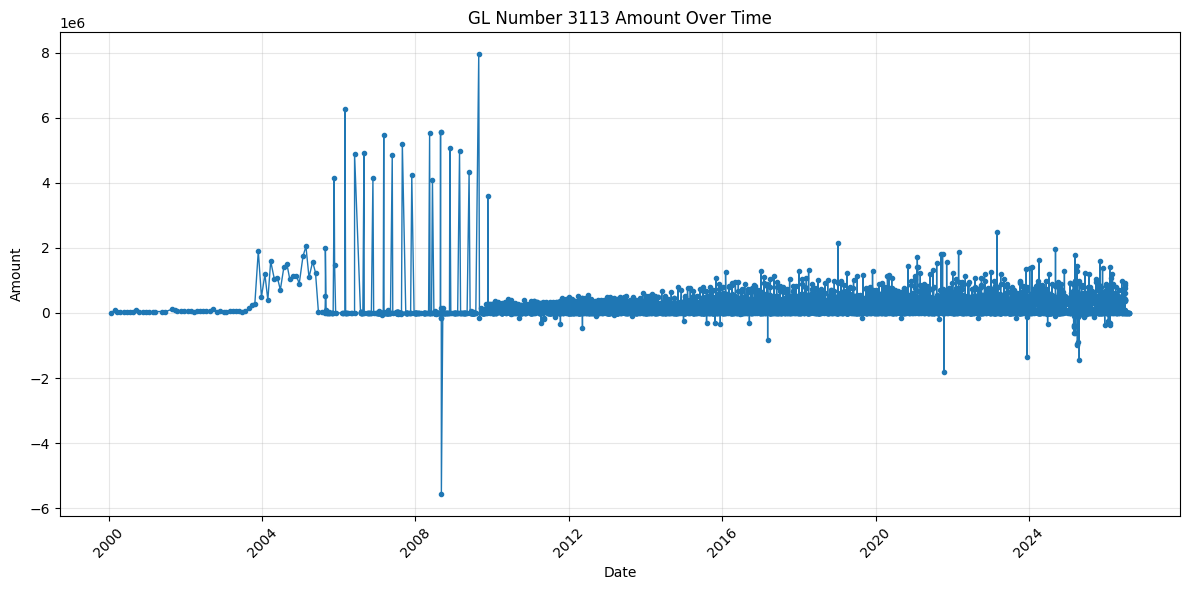

(9383,
 [{'Doc Number': 'JV 130 J36833',
   'Date': datetime.datetime(2000, 1, 20, 0, 0),
   'Amount': 12335.51,
   'level_1_id': '2004',
   'level_2_id': '3036',
   'GL Number': '3113',
   'description': 'BUSINESS LICENSE FEES',
   'Type': 'Minor',
   'BA Number': '9999',
   'fy': '2000'},
  {'Doc Number': 'JV 130 J40929',
   'Date': datetime.datetime(2000, 3, 1, 0, 0),
   'Amount': 82817.26,
   'level_1_id': '2004',
   'level_2_id': '3036',
   'GL Number': '3113',
   'description': 'BUSINESS LICENSE FEES',
   'Type': 'Minor',
   'BA Number': '9999',
   'fy': '2000'},
  {'Doc Number': 'JV 130 J45015',
   'Date': datetime.datetime(2000, 3, 21, 0, 0),
   'Amount': 36832.56,
   'level_1_id': '2004',
   'level_2_id': '3036',
   'GL Number': '3113',
   'description': 'BUSINESS LICENSE FEES',
   'Type': 'Minor',
   'BA Number': '9999',
   'fy': '2000'}])

In [8]:
from datetime import datetime
import matplotlib.pyplot as plt


def parse_date(value):
    for fmt in ("%Y-%m-%d", "%m/%d/%Y", "%m/%d/%y"):
        try:
            return datetime.strptime(str(value).strip(), fmt)
        except ValueError:
            pass
    return None


gl_3113_df = [
    {
        **row,
        "Date": parse_date(row.get("Date", "")),
    }
    for row in df
    if str(row.get("GL Number", "")).strip() == "3113"
]

gl_3113_df = [row for row in gl_3113_df if row["Date"] is not None]
gl_3113_df = sorted(gl_3113_df, key=lambda row: row["Date"])

dates = [row["Date"] for row in gl_3113_df]
amounts = [row["Amount"] for row in gl_3113_df]

plt.figure(figsize=(12, 6))
plt.plot(dates, amounts, marker="o", linewidth=1, markersize=3)
plt.title("GL Number 3113 Amount Over Time")
plt.xlabel("Date")
plt.ylabel("Amount")
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

len(gl_3113_df), gl_3113_df[:3]

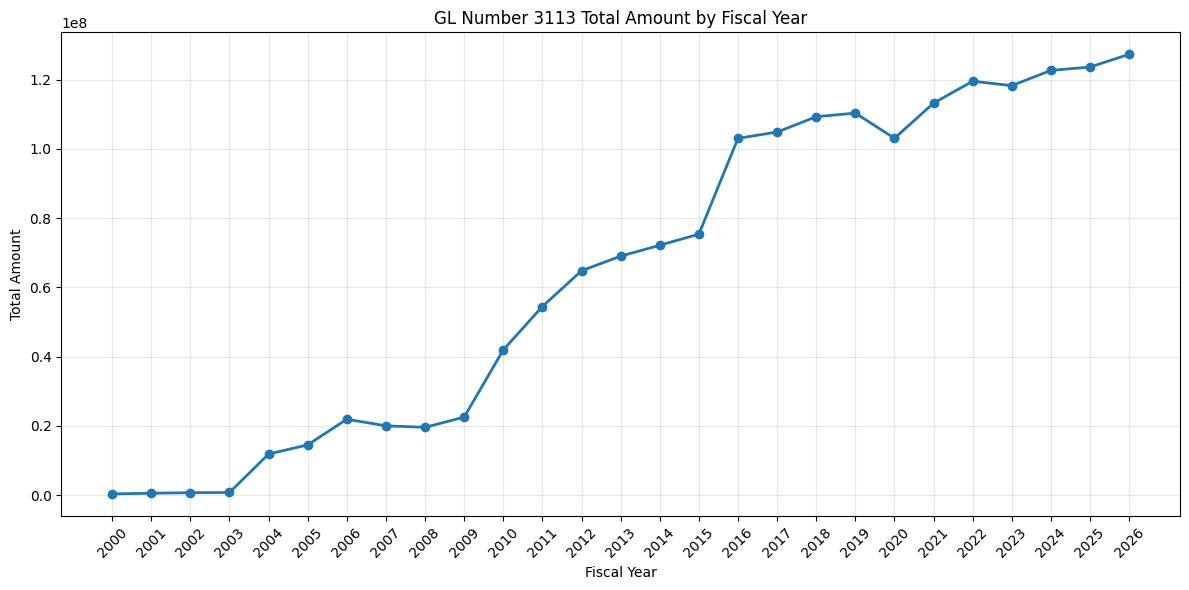

[{'fy': '2000', 'total_amount': 325739.75},
 {'fy': '2001', 'total_amount': 523072.4600000001},
 {'fy': '2002', 'total_amount': 680844.9999999999},
 {'fy': '2003', 'total_amount': 739560.7000000002},
 {'fy': '2004', 'total_amount': 11851752.48},
 {'fy': '2005', 'total_amount': 14486314.690000001},
 {'fy': '2006', 'total_amount': 21897094.63},
 {'fy': '2007', 'total_amount': 19997652.59},
 {'fy': '2008', 'total_amount': 19566389.9},
 {'fy': '2009', 'total_amount': 22516701.930000003},
 {'fy': '2010', 'total_amount': 41940369.95},
 {'fy': '2011', 'total_amount': 54466138.26999999},
 {'fy': '2012', 'total_amount': 64790426.32999998},
 {'fy': '2013', 'total_amount': 69010684.88000001},
 {'fy': '2014', 'total_amount': 72166481.77000001},
 {'fy': '2015', 'total_amount': 75359976.07000001},
 {'fy': '2016', 'total_amount': 103045618.67999999},
 {'fy': '2017', 'total_amount': 104858331.15},
 {'fy': '2018', 'total_amount': 109297773.16000001},
 {'fy': '2019', 'total_amount': 110336678.32},
 {'fy

In [9]:
gl_3113_by_fy = defaultdict(float)

for row in gl_3113_df:
    fy = str(row.get("fy", "")).strip()
    if fy:
        gl_3113_by_fy[fy] += row["Amount"]

gl_3113_fy_series = [
    {"fy": fy, "total_amount": amount}
    for fy, amount in sorted(gl_3113_by_fy.items(), key=lambda item: int(item[0]))
]

fy_values = [row["fy"] for row in gl_3113_fy_series]
fy_amounts = [row["total_amount"] for row in gl_3113_fy_series]

plt.figure(figsize=(12, 6))
plt.plot(fy_values, fy_amounts, marker="o", linewidth=2)
plt.title("GL Number 3113 Total Amount by Fiscal Year")
plt.xlabel("Fiscal Year")
plt.ylabel("Total Amount")
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

gl_3113_fy_series

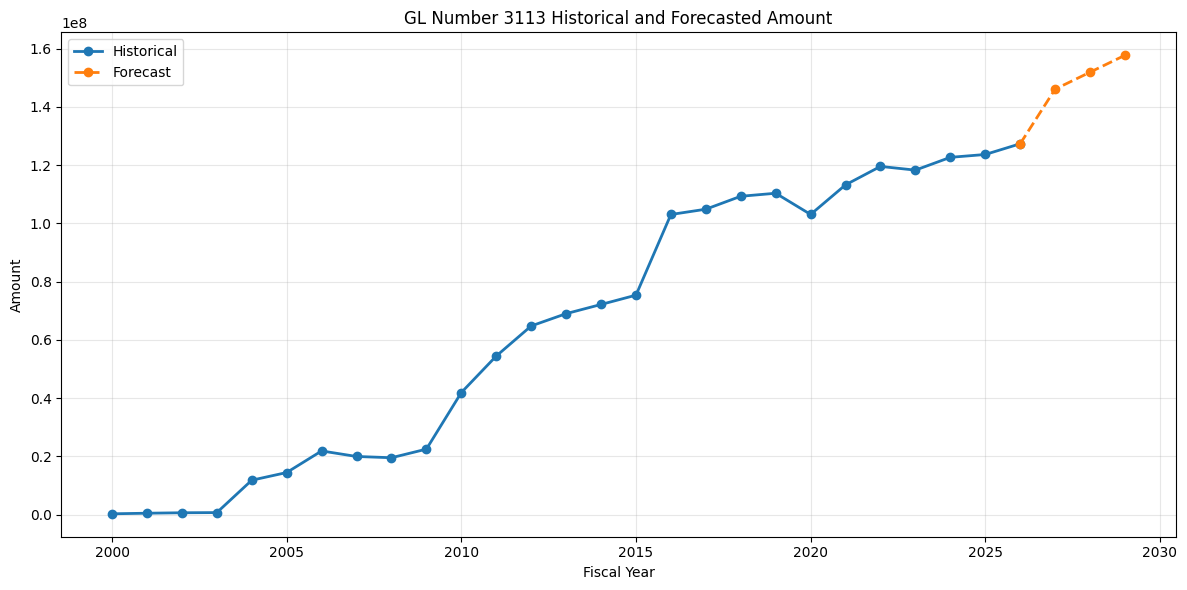

[{'fy': '2027', 'predicted_amount': 146062288.94290543},
 {'fy': '2028', 'predicted_amount': 151877399.63470078},
 {'fy': '2029', 'predicted_amount': 157692510.32649612}]

In [10]:
historical_years = [int(row["fy"]) for row in gl_3113_fy_series]
historical_amounts = [row["total_amount"] for row in gl_3113_fy_series]

x_mean = sum(historical_years) / len(historical_years)
y_mean = sum(historical_amounts) / len(historical_amounts)

slope = sum(
    (x - x_mean) * (y - y_mean)
    for x, y in zip(historical_years, historical_amounts)
) / sum((x - x_mean) ** 2 for x in historical_years)
intercept = y_mean - slope * x_mean

last_fy = max(historical_years)
forecast_years = [last_fy + i for i in range(1, 4)]
forecast_amounts = [intercept + slope * fy for fy in forecast_years]

gl_3113_forecast = [
    {
        "fy": str(fy),
        "predicted_amount": amount,
    }
    for fy, amount in zip(forecast_years, forecast_amounts)
]

plt.figure(figsize=(12, 6))
plt.plot(historical_years, historical_amounts, marker="o", linewidth=2, label="Historical")
plt.plot(
    [last_fy, *forecast_years],
    [historical_amounts[-1], *forecast_amounts],
    marker="o",
    linestyle="--",
    linewidth=2,
    label="Forecast",
)
plt.title("GL Number 3113 Historical and Forecasted Amount")
plt.xlabel("Fiscal Year")
plt.ylabel("Amount")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

gl_3113_forecast

## Holt-Winter Model

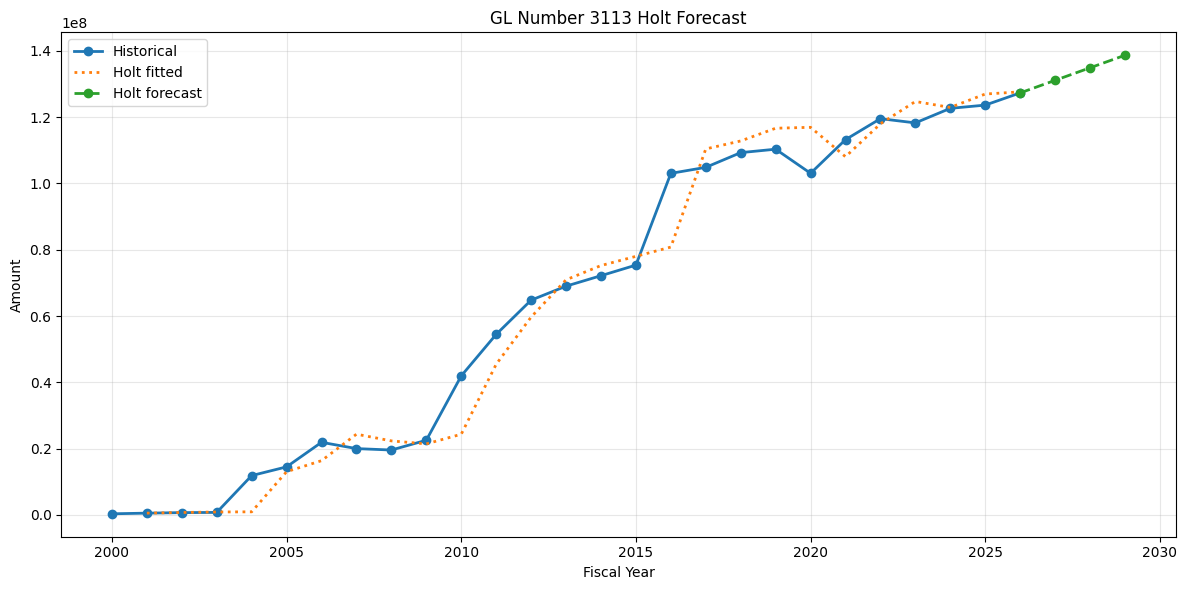

[{'fy': '2027',
  'predicted_amount': 131114195.03392059,
  'method': 'Holt linear smoothing',
  'alpha': 0.95,
  'beta': 0.15},
 {'fy': '2028',
  'predicted_amount': 134895571.90959403,
  'method': 'Holt linear smoothing',
  'alpha': 0.95,
  'beta': 0.15},
 {'fy': '2029',
  'predicted_amount': 138676948.7852675,
  'method': 'Holt linear smoothing',
  'alpha': 0.95,
  'beta': 0.15}]

In [11]:
def holt_linear_forecast(values, periods=3, alpha=0.8, beta=0.2):
    if len(values) < 2:
        raise ValueError("Holt smoothing needs at least two historical values.")

    level = values[0]
    trend = values[1] - values[0]
    fitted = [None]

    for value in values[1:]:
        forecast = level + trend
        fitted.append(forecast)

        previous_level = level
        level = alpha * value + (1 - alpha) * (level + trend)
        trend = beta * (level - previous_level) + (1 - beta) * trend

    forecast_values = [level + step * trend for step in range(1, periods + 1)]
    return forecast_values, fitted, level, trend


def holt_sse(values, alpha, beta):
    _, fitted, _, _ = holt_linear_forecast(values, alpha=alpha, beta=beta)
    errors = [value - fit for value, fit in zip(values[1:], fitted[1:])]
    return sum(error ** 2 for error in errors)


alpha_beta_grid = [i / 20 for i in range(1, 20)]
best_alpha, best_beta, best_sse = min(
    (
        (alpha, beta, holt_sse(historical_amounts, alpha, beta))
        for alpha in alpha_beta_grid
        for beta in alpha_beta_grid
    ),
    key=lambda item: item[2],
)

holt_forecast_amounts, holt_fitted, holt_level, holt_trend = holt_linear_forecast(
    historical_amounts,
    periods=3,
    alpha=best_alpha,
    beta=best_beta,
)

holt_forecast_years = [last_fy + i for i in range(1, 4)]
gl_3113_holt_forecast = [
    {
        "fy": str(fy),
        "predicted_amount": amount,
        "method": "Holt linear smoothing",
        "alpha": best_alpha,
        "beta": best_beta,
    }
    for fy, amount in zip(holt_forecast_years, holt_forecast_amounts)
]

plt.figure(figsize=(12, 6))
plt.plot(historical_years, historical_amounts, marker="o", linewidth=2, label="Historical")
plt.plot(
    historical_years[1:],
    holt_fitted[1:],
    linestyle=":",
    linewidth=2,
    label="Holt fitted",
)
plt.plot(
    [last_fy, *holt_forecast_years],
    [historical_amounts[-1], *holt_forecast_amounts],
    marker="o",
    linestyle="--",
    linewidth=2,
    label="Holt forecast",
)
plt.title("GL Number 3113 Holt Forecast")
plt.xlabel("Fiscal Year")
plt.ylabel("Amount")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

gl_3113_holt_forecast

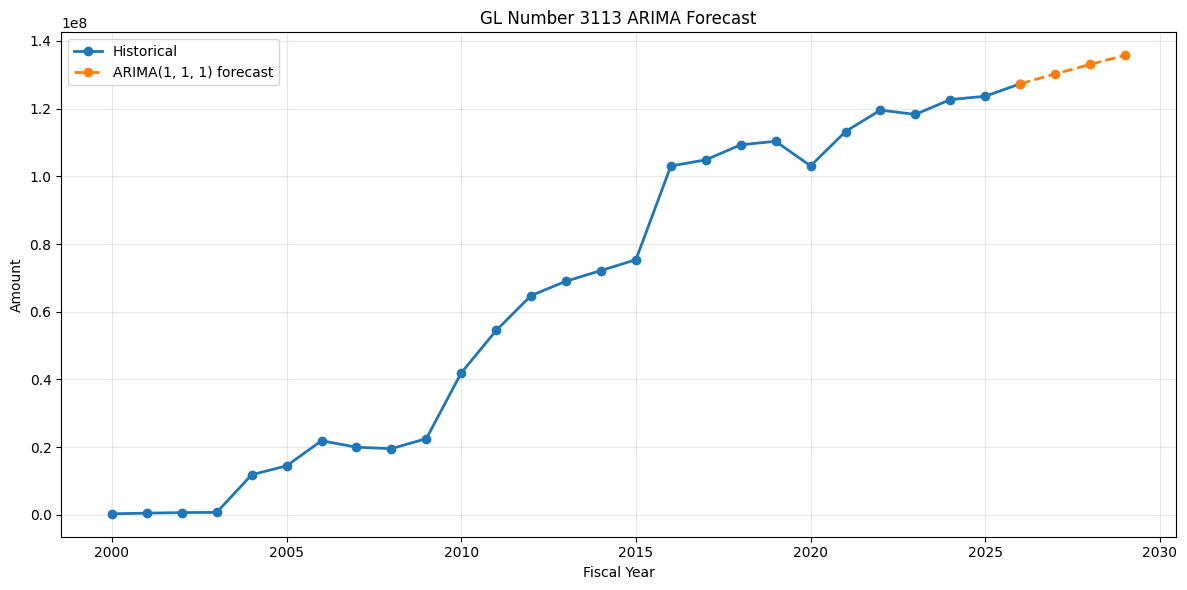

[{'fy': '2027',
  'predicted_amount': 130226600.20723666,
  'method': 'ARIMA(1, 1, 1)'},
 {'fy': '2028',
  'predicted_amount': 133034833.14027812,
  'method': 'ARIMA(1, 1, 1)'},
 {'fy': '2029',
  'predicted_amount': 135745357.2326605,
  'method': 'ARIMA(1, 1, 1)'}]

In [12]:
from statsmodels.tsa.arima.model import ARIMA

arima_order = (1, 1, 1)
arima_model = ARIMA(historical_amounts, order=arima_order)
arima_result = arima_model.fit()

arima_forecast_amounts = arima_result.forecast(steps=3).tolist()
arima_forecast_years = [last_fy + i for i in range(1, 4)]

gl_3113_arima_forecast = [
    {
        "fy": str(fy),
        "predicted_amount": amount,
        "method": f"ARIMA{arima_order}",
    }
    for fy, amount in zip(arima_forecast_years, arima_forecast_amounts)
]

plt.figure(figsize=(12, 6))
plt.plot(historical_years, historical_amounts, marker="o", linewidth=2, label="Historical")
plt.plot(
    [last_fy, *arima_forecast_years],
    [historical_amounts[-1], *arima_forecast_amounts],
    marker="o",
    linestyle="--",
    linewidth=2,
    label=f"ARIMA{arima_order} forecast",
)
plt.title("GL Number 3113 ARIMA Forecast")
plt.xlabel("Fiscal Year")
plt.ylabel("Amount")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

gl_3113_arima_forecast

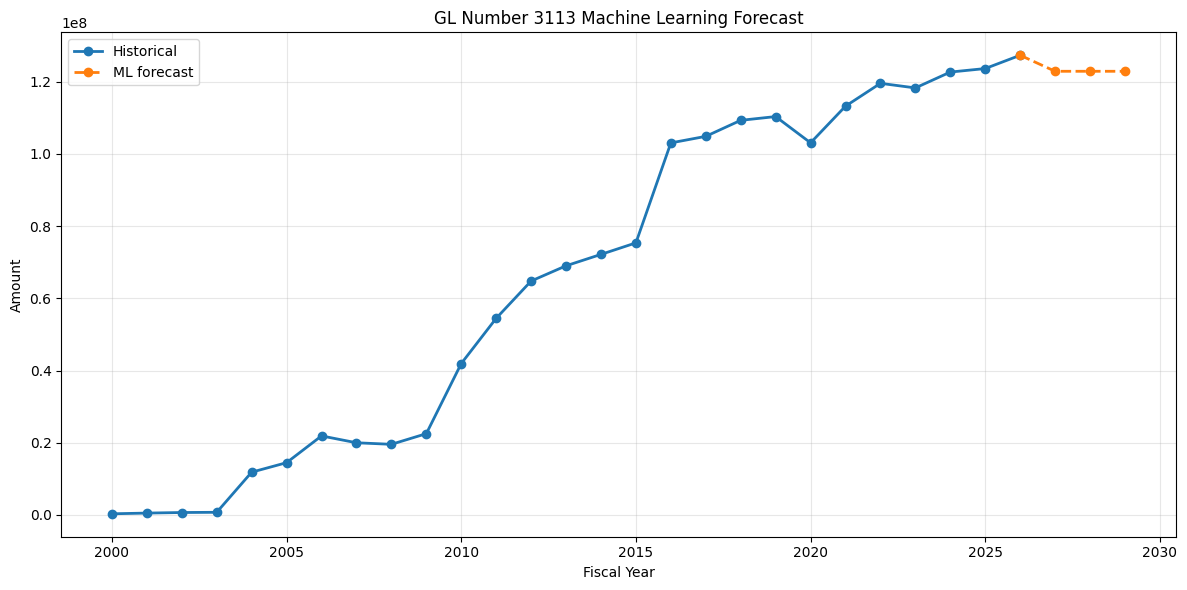

[{'fy': '2027',
  'predicted_amount': 122880052.56445558,
  'method': 'Random Forest regression with 3 FY lags'},
 {'fy': '2028',
  'predicted_amount': 122880052.56445558,
  'method': 'Random Forest regression with 3 FY lags'},
 {'fy': '2029',
  'predicted_amount': 122880052.56445558,
  'method': 'Random Forest regression with 3 FY lags'}]

In [13]:
from sklearn.ensemble import RandomForestRegressor

lag_count = 3
X = []
y = []

for i in range(lag_count, len(historical_amounts)):
    X.append([
        historical_years[i],
        historical_amounts[i - 1],
        historical_amounts[i - 2],
        historical_amounts[i - 3],
    ])
    y.append(historical_amounts[i])

ml_model = RandomForestRegressor(
    n_estimators=500,
    random_state=42,
    min_samples_leaf=2,
)
ml_model.fit(X, y)

ml_forecast_years = [last_fy + i for i in range(1, 4)]
ml_history_for_prediction = historical_amounts.copy()
ml_forecast_amounts = []

for fy in ml_forecast_years:
    features = [[
        fy,
        ml_history_for_prediction[-1],
        ml_history_for_prediction[-2],
        ml_history_for_prediction[-3],
    ]]
    predicted_amount = float(ml_model.predict(features)[0])
    ml_forecast_amounts.append(predicted_amount)
    ml_history_for_prediction.append(predicted_amount)

gl_3113_ml_forecast = [
    {
        "fy": str(fy),
        "predicted_amount": amount,
        "method": "Random Forest regression with 3 FY lags",
    }
    for fy, amount in zip(ml_forecast_years, ml_forecast_amounts)
]

plt.figure(figsize=(12, 6))
plt.plot(historical_years, historical_amounts, marker="o", linewidth=2, label="Historical")
plt.plot(
    [last_fy, *ml_forecast_years],
    [historical_amounts[-1], *ml_forecast_amounts],
    marker="o",
    linestyle="--",
    linewidth=2,
    label="ML forecast",
)
plt.title("GL Number 3113 Machine Learning Forecast")
plt.xlabel("Fiscal Year")
plt.ylabel("Amount")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

gl_3113_ml_forecast

## Step-by-Step Time-Series Forecasting Procedure

1. Define the target series: filter the dataset to the revenue account of interest, here `GL Number == 3113`.

2. Aggregate to the forecasting frequency: because the requested forecast is by fiscal year, group the data by `fy` and sum `Amount` for each year.

3. Sort the time series: order fiscal years from oldest to newest so the model learns the revenue pattern in the correct sequence.

4. Plot the historical series: inspect whether the series has trend, outliers, sudden jumps, or flat periods before choosing a model.

5. Choose candidate models: compare simple trend regression, Holt linear smoothing, ARIMA, and machine learning models with lag features.

6. Fit the model on historical values: use past fiscal-year totals as the training data. For machine learning, create lag variables such as previous 1, 2, and 3 fiscal-year amounts.

7. Validate model behavior: check whether forecasts are reasonable compared with recent years and whether the predicted direction matches the historical trend.

8. Forecast the next three fiscal years: use the fitted model to predict FY 2027, FY 2028, and FY 2029 if FY 2026 is the latest year in the dataset.

9. Plot historical and predicted values together: show actual amounts as a solid line and forecasted amounts as a dashed line.

10. Compare models before final use: place linear trend, Holt, ARIMA, and ML forecasts side by side, then select the method that is most defensible for reporting.

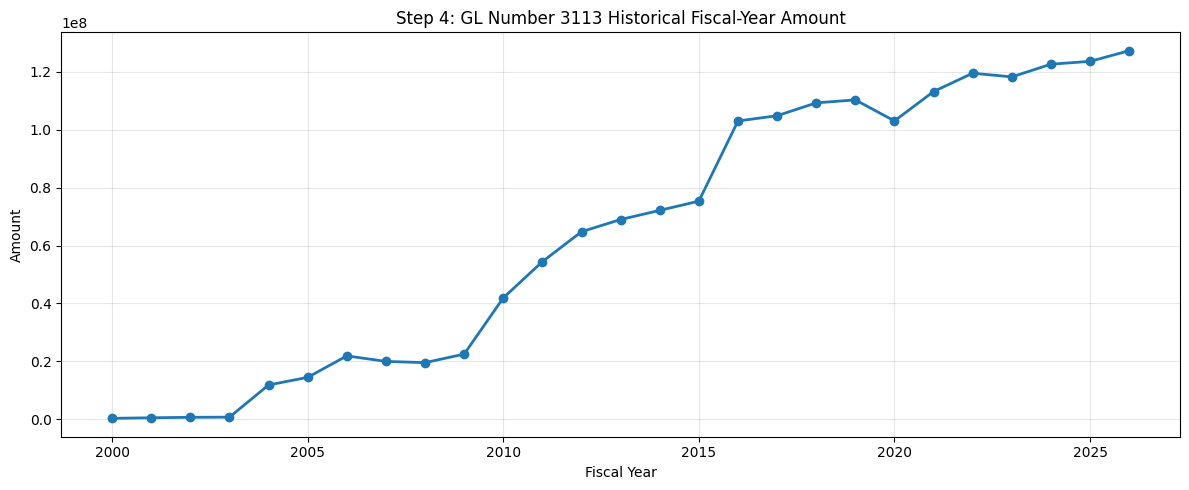

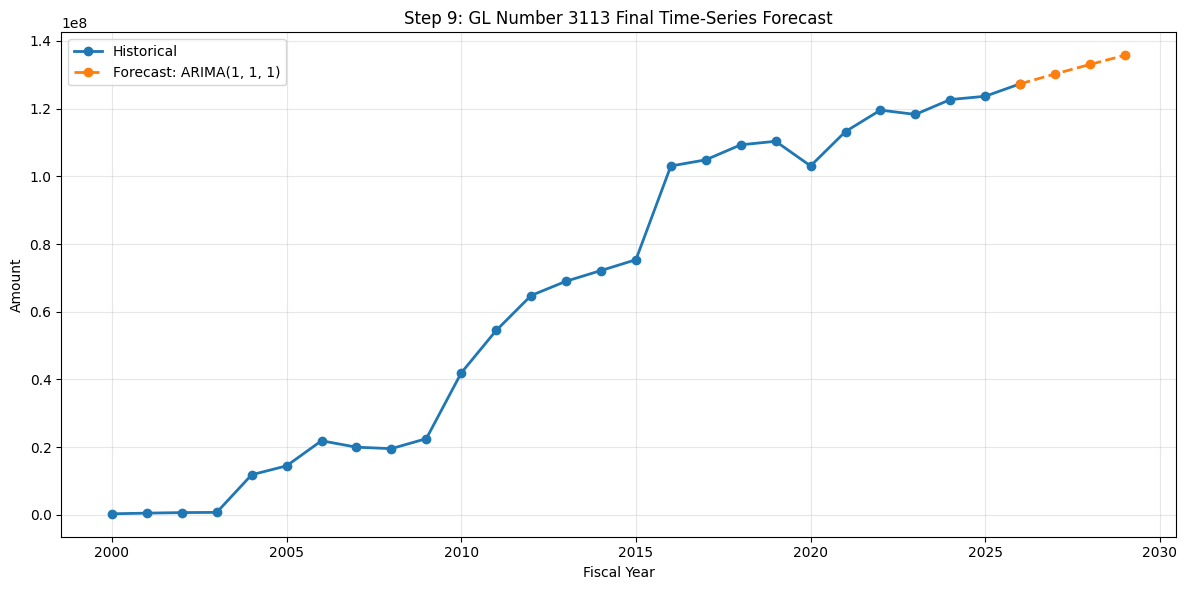

Model,Validation MAE,Validation MAPE
"ARIMA(1, 1, 1)","$733,991.34",0.60%
Holt linear smoothing,"$2,735,548.76",2.18%
Random Forest lag model,"$9,972,793.59",7.98%
Linear trend,"$15,914,647.91",12.75%
FY,Predicted Amount,Selected Model
2027,"$130,226,600.21","ARIMA(1, 1, 1)"
2028,"$133,034,833.14","ARIMA(1, 1, 1)"
2029,"$135,745,357.23","ARIMA(1, 1, 1)"


In [14]:
from sklearn.ensemble import RandomForestRegressor
from statsmodels.tsa.arima.model import ARIMA
import warnings


# Step 1-3: create the GL 3113 fiscal-year time series.
ts_3113 = [
    (int(row["fy"]), row["total_amount"])
    for row in gl_3113_fy_series
    if str(row.get("fy", "")).strip().isdigit()
]
ts_3113 = sorted(ts_3113, key=lambda item: item[0])

years = [item[0] for item in ts_3113]
amounts = [item[1] for item in ts_3113]


# Step 4: plot the historical series.
plt.figure(figsize=(12, 5))
plt.plot(years, amounts, marker="o", linewidth=2)
plt.title("Step 4: GL Number 3113 Historical Fiscal-Year Amount")
plt.xlabel("Fiscal Year")
plt.ylabel("Amount")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# Step 5-7: train candidate models and compare them on the last 3 historical years.
holdout_size = 3
train_years = years[:-holdout_size]
train_amounts = amounts[:-holdout_size]
test_years = years[-holdout_size:]
test_amounts = amounts[-holdout_size:]


def mean_absolute_error(actual, predicted):
    return sum(abs(a - p) for a, p in zip(actual, predicted)) / len(actual)


def mean_absolute_percentage_error(actual, predicted):
    return sum(abs((a - p) / a) for a, p in zip(actual, predicted) if a != 0) / len(actual)


def linear_trend_predict(fit_years, fit_amounts, predict_years):
    x_mean = sum(fit_years) / len(fit_years)
    y_mean = sum(fit_amounts) / len(fit_amounts)
    slope = sum(
        (x - x_mean) * (y - y_mean)
        for x, y in zip(fit_years, fit_amounts)
    ) / sum((x - x_mean) ** 2 for x in fit_years)
    intercept = y_mean - slope * x_mean
    return [intercept + slope * year for year in predict_years]


def holt_predict(fit_amounts, periods):
    grid = [i / 20 for i in range(1, 20)]
    alpha, beta, _ = min(
        (
            (a, b, holt_sse(fit_amounts, a, b))
            for a in grid
            for b in grid
        ),
        key=lambda item: item[2],
    )
    forecast, _, _, _ = holt_linear_forecast(fit_amounts, periods=periods, alpha=alpha, beta=beta)
    return forecast, alpha, beta


def arima_predict(fit_amounts, periods, order=(1, 1, 1)):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        model = ARIMA(fit_amounts, order=order)
        result = model.fit()
    return result.forecast(steps=periods).tolist()


def random_forest_lag_predict(fit_years, fit_amounts, predict_years, lag=3):
    X_train = []
    y_train = []

    for i in range(lag, len(fit_amounts)):
        X_train.append([
            fit_years[i],
            fit_amounts[i - 1],
            fit_amounts[i - 2],
            fit_amounts[i - 3],
        ])
        y_train.append(fit_amounts[i])

    model = RandomForestRegressor(n_estimators=500, random_state=42, min_samples_leaf=2)
    model.fit(X_train, y_train)

    history = fit_amounts.copy()
    predictions = []

    for year in predict_years:
        prediction = float(model.predict([[
            year,
            history[-1],
            history[-2],
            history[-3],
        ]])[0])
        predictions.append(prediction)
        history.append(prediction)

    return predictions


candidate_predictions = {
    "Linear trend": linear_trend_predict(train_years, train_amounts, test_years),
    "Holt linear smoothing": holt_predict(train_amounts, holdout_size)[0],
    "ARIMA(1, 1, 1)": arima_predict(train_amounts, holdout_size),
    "Random Forest lag model": random_forest_lag_predict(train_years, train_amounts, test_years),
}

model_comparison = []

for model_name, predictions in candidate_predictions.items():
    model_comparison.append({
        "model": model_name,
        "validation_mae": mean_absolute_error(test_amounts, predictions),
        "validation_mape": mean_absolute_percentage_error(test_amounts, predictions),
    })

model_comparison = sorted(model_comparison, key=lambda row: row["validation_mae"])
best_model_name = model_comparison[0]["model"]


# Step 8: refit the best model on all history and forecast the next 3 fiscal years.
future_years = [years[-1] + i for i in range(1, 4)]

if best_model_name == "Linear trend":
    final_forecast_amounts = linear_trend_predict(years, amounts, future_years)
elif best_model_name == "Holt linear smoothing":
    final_forecast_amounts = holt_predict(amounts, 3)[0]
elif best_model_name == "ARIMA(1, 1, 1)":
    final_forecast_amounts = arima_predict(amounts, 3)
else:
    final_forecast_amounts = random_forest_lag_predict(years, amounts, future_years)

final_time_series_forecast = [
    {
        "fy": str(year),
        "predicted_amount": amount,
        "selected_model": best_model_name,
    }
    for year, amount in zip(future_years, final_forecast_amounts)
]


# Step 9: plot historical and predicted values together.
plt.figure(figsize=(12, 6))
plt.plot(years, amounts, marker="o", linewidth=2, label="Historical")
plt.plot(
    [years[-1], *future_years],
    [amounts[-1], *final_forecast_amounts],
    marker="o",
    linestyle="--",
    linewidth=2,
    label=f"Forecast: {best_model_name}",
)
plt.title("Step 9: GL Number 3113 Final Time-Series Forecast")
plt.xlabel("Fiscal Year")
plt.ylabel("Amount")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# Step 10: show model comparison and final forecast.
comparison_rows = "".join(
    f"<tr><td>{escape(row['model'])}</td><td>{money(row['validation_mae'])}</td><td>{pct(row['validation_mape'])}</td></tr>"
    for row in model_comparison
)
forecast_rows = "".join(
    f"<tr><td>{row['fy']}</td><td>{money(row['predicted_amount'])}</td><td>{escape(row['selected_model'])}</td></tr>"
    for row in final_time_series_forecast
)

summary_html = f"""
    <h3>Step 10: Model Comparison</h3>
    <table>
        <thead><tr><th>Model</th><th>Validation MAE</th><th>Validation MAPE</th></tr></thead>
        <tbody>{comparison_rows}</tbody>
    </table>
    <h3>Final 3-Year Forecast</h3>
    <table>
        <thead><tr><th>FY</th><th>Predicted Amount</th><th>Selected Model</th></tr></thead>
        <tbody>{forecast_rows}</tbody>
    </table>
"""

display(HTML(summary_html) if HTML else {"comparison": model_comparison, "forecast": final_time_series_forecast})

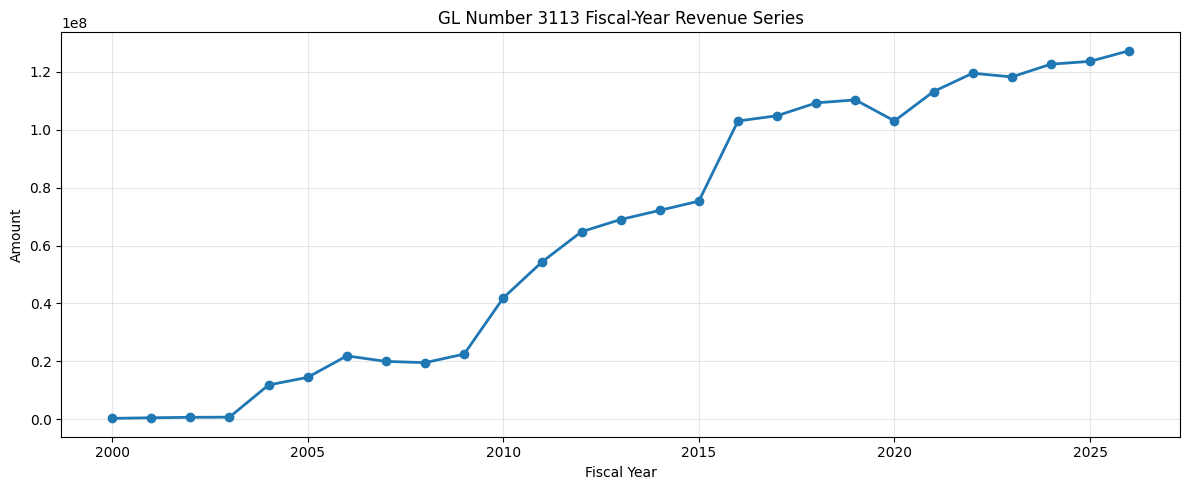

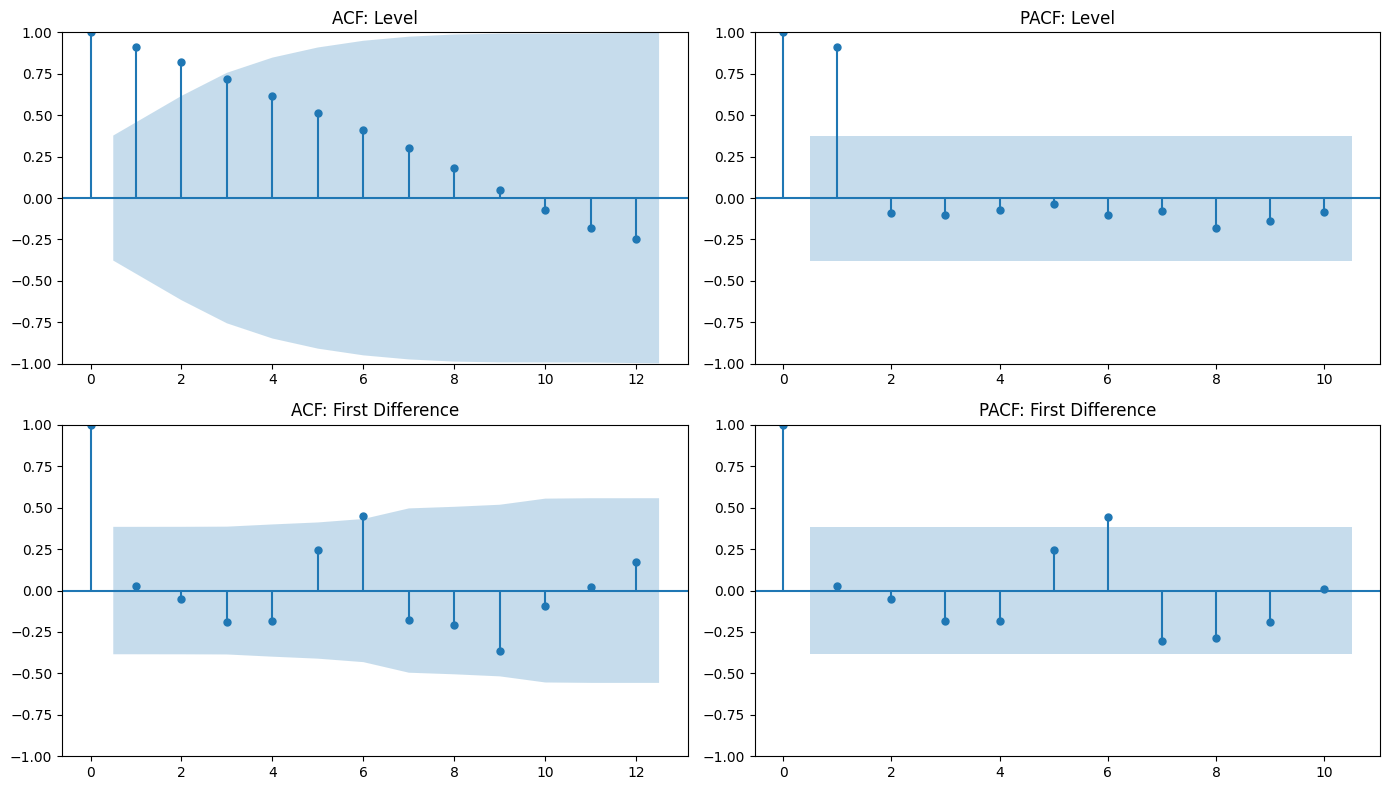

Series,ADF statistic,p-value,Used lag,N obs,1% critical,5% critical,10% critical,Stationary at 5%
Level,-1.5192,0.5240,6,20,-3.8092,-3.0216,-2.6507,No
First difference,-2.9748,0.0373,8,17,-3.8893,-3.0544,-2.6670,Yes


Order,AIC,BIC,HQIC,Converged
"(1, 1, 1)",903.37,907.14,904.45,True
"(1, 1, 0)",904.40,906.91,905.12,True
"(0, 1, 4)",905.22,911.51,907.03,True
"(2, 1, 1)",905.33,910.36,906.78,True
"(2, 1, 0)",905.33,909.10,906.42,True
"(0, 1, 3)",905.54,910.57,906.99,True
"(1, 1, 2)",905.61,910.64,907.06,True
"(0, 1, 1)",905.65,908.17,906.37,True
"(2, 1, 4)",905.66,914.47,908.20,False
"(0, 1, 2)",905.69,909.46,906.77,True


Test,Lag,Statistic,p-value,Interpretation
Ljung-Box autocorrelation test,10,19.3402,0.0361,Residual autocorrelation may remain at 5%


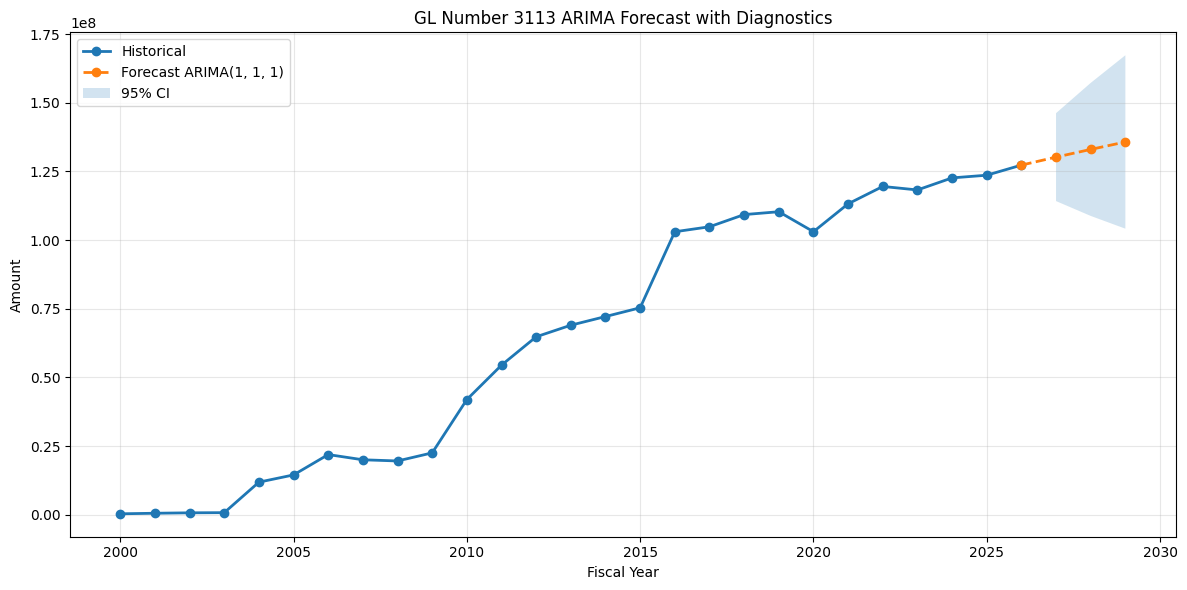

FY,Predicted Amount,Lower 95% CI,Upper 95% CI,Selected Order
2027,"$130,226,600.21","$114,214,419.09","$146,238,781.32","(1, 1, 1)"
2028,"$133,034,833.14","$108,812,939.78","$157,256,726.50","(1, 1, 1)"
2029,"$135,745,357.23","$104,166,470.57","$167,324,243.90","(1, 1, 1)"


In [15]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
import warnings


# 1. Prepare and plot the GL 3113 fiscal-year series.
arima_series = [
    (int(row["fy"]), row["total_amount"])
    for row in gl_3113_fy_series
    if str(row.get("fy", "")).strip().isdigit()
]
arima_series = sorted(arima_series, key=lambda item: item[0])

arima_years = [item[0] for item in arima_series]
arima_amounts = [item[1] for item in arima_series]
arima_first_difference = [
    arima_amounts[i] - arima_amounts[i - 1]
    for i in range(1, len(arima_amounts))
]

plt.figure(figsize=(12, 5))
plt.plot(arima_years, arima_amounts, marker="o", linewidth=2)
plt.title("GL Number 3113 Fiscal-Year Revenue Series")
plt.xlabel("Fiscal Year")
plt.ylabel("Amount")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# 2. Plot ACF and PACF for the level and first-differenced series.
acf_lags = min(12, len(arima_amounts) - 2)
pacf_lags = min(10, len(arima_amounts) // 2 - 1)

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
plot_acf(arima_amounts, lags=acf_lags, ax=axes[0, 0])
axes[0, 0].set_title("ACF: Level")
plot_pacf(arima_amounts, lags=pacf_lags, ax=axes[0, 1], method="ywm")
axes[0, 1].set_title("PACF: Level")
plot_acf(arima_first_difference, lags=min(acf_lags, len(arima_first_difference) - 2), ax=axes[1, 0])
axes[1, 0].set_title("ACF: First Difference")
plot_pacf(arima_first_difference, lags=min(pacf_lags, len(arima_first_difference) // 2 - 1), ax=axes[1, 1], method="ywm")
axes[1, 1].set_title("PACF: First Difference")
plt.tight_layout()
plt.show()


# 3. Unit-root tests for level and first difference.
def adf_result(values, series_name):
    test_stat, p_value, used_lag, n_obs, critical_values, icbest = adfuller(values, autolag="AIC")
    return {
        "series": series_name,
        "adf_statistic": test_stat,
        "p_value": p_value,
        "used_lag": used_lag,
        "n_obs": n_obs,
        "critical_1pct": critical_values["1%"],
        "critical_5pct": critical_values["5%"],
        "critical_10pct": critical_values["10%"],
        "stationary_at_5pct": "Yes" if p_value <= 0.05 else "No",
    }


unit_root_tests = [
    adf_result(arima_amounts, "Level"),
    adf_result(arima_first_difference, "First difference"),
]

unit_root_rows = "".join(
    f"<tr><td>{row['series']}</td><td>{row['adf_statistic']:.4f}</td><td>{row['p_value']:.4f}</td>"
    f"<td>{row['used_lag']}</td><td>{row['n_obs']}</td><td>{row['critical_1pct']:.4f}</td>"
    f"<td>{row['critical_5pct']:.4f}</td><td>{row['critical_10pct']:.4f}</td><td>{row['stationary_at_5pct']}</td></tr>"
    for row in unit_root_tests
)

unit_root_html = f"""
    <h3>ADF Unit-Root Test</h3>
    <table>
        <thead>
            <tr><th>Series</th><th>ADF statistic</th><th>p-value</th><th>Used lag</th><th>N obs</th><th>1% critical</th><th>5% critical</th><th>10% critical</th><th>Stationary at 5%</th></tr>
        </thead>
        <tbody>{unit_root_rows}</tbody>
    </table>
"""
display(HTML(unit_root_html) if HTML else unit_root_tests)


# 4. Select differencing order and search ARIMA lag orders.
selected_d = 0 if unit_root_tests[0]["p_value"] <= 0.05 else 1
if selected_d == 1 and unit_root_tests[1]["p_value"] > 0.05:
    selected_d = 2

order_results = []
max_p = 4
max_q = 4

for p in range(max_p + 1):
    for q in range(max_q + 1):
        if p == 0 and q == 0:
            continue
        order = (p, selected_d, q)
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                result = ARIMA(arima_amounts, order=order).fit()
            order_results.append({
                "order": order,
                "aic": result.aic,
                "bic": result.bic,
                "hqic": result.hqic,
                "converged": result.mle_retvals.get("converged", None),
            })
        except Exception as exc:
            order_results.append({
                "order": order,
                "aic": None,
                "bic": None,
                "hqic": None,
                "converged": False,
                "error": str(exc),
            })

valid_order_results = [row for row in order_results if row["aic"] is not None]
valid_order_results = sorted(valid_order_results, key=lambda row: row["aic"])
selected_order = valid_order_results[0]["order"]

order_rows = "".join(
    f"<tr><td>{row['order']}</td><td>{row['aic']:.2f}</td><td>{row['bic']:.2f}</td><td>{row['hqic']:.2f}</td><td>{row['converged']}</td></tr>"
    for row in valid_order_results[:10]
)

order_html = f"""
    <h3>ARIMA Order Search by AIC</h3>
    <p>Selected differencing order d = {selected_d}. Showing the 10 best fitted orders.</p>
    <table>
        <thead><tr><th>Order</th><th>AIC</th><th>BIC</th><th>HQIC</th><th>Converged</th></tr></thead>
        <tbody>{order_rows}</tbody>
    </table>
"""
display(HTML(order_html) if HTML else valid_order_results[:10])


# 5. Fit selected ARIMA model and run residual diagnostic tests.
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    selected_arima_result = ARIMA(arima_amounts, order=selected_order).fit()

diagnostic_lag = min(10, len(arima_amounts) // 2 - 1)
ljung_box = acorr_ljungbox(selected_arima_result.resid, lags=[diagnostic_lag], return_df=True)
ljung_box_stat = float(ljung_box["lb_stat"].iloc[0])
ljung_box_pvalue = float(ljung_box["lb_pvalue"].iloc[0])

diagnostic_html = f"""
    <h3>Residual Diagnostic Test</h3>
    <table>
        <thead><tr><th>Test</th><th>Lag</th><th>Statistic</th><th>p-value</th><th>Interpretation</th></tr></thead>
        <tbody>
            <tr>
                <td>Ljung-Box autocorrelation test</td>
                <td>{diagnostic_lag}</td>
                <td>{ljung_box_stat:.4f}</td>
                <td>{ljung_box_pvalue:.4f}</td>
                <td>{'Residual autocorrelation not detected at 5%' if ljung_box_pvalue > 0.05 else 'Residual autocorrelation may remain at 5%'}</td>
            </tr>
        </tbody>
    </table>
"""
display(HTML(diagnostic_html) if HTML else {"ljung_box_stat": ljung_box_stat, "ljung_box_pvalue": ljung_box_pvalue})


# 6. Show ARIMA regression/model summary.
display(HTML(selected_arima_result.summary().as_html()) if HTML else selected_arima_result.summary())


# 7. Predict the next 3 fiscal years and plot historical plus forecast.
forecast_steps = 3
final_arima_forecast_years = [arima_years[-1] + i for i in range(1, forecast_steps + 1)]
forecast_result = selected_arima_result.get_forecast(steps=forecast_steps)
final_arima_forecast_amounts = forecast_result.predicted_mean.tolist()
confidence_interval = forecast_result.conf_int(alpha=0.05)

try:
    lower_ci = confidence_interval.iloc[:, 0].tolist()
    upper_ci = confidence_interval.iloc[:, 1].tolist()
except AttributeError:
    lower_ci = [row[0] for row in confidence_interval]
    upper_ci = [row[1] for row in confidence_interval]

final_arima_forecast = [
    {
        "fy": str(fy),
        "predicted_amount": amount,
        "lower_95_ci": low,
        "upper_95_ci": high,
        "selected_order": selected_order,
    }
    for fy, amount, low, high in zip(
        final_arima_forecast_years,
        final_arima_forecast_amounts,
        lower_ci,
        upper_ci,
    )
]

plt.figure(figsize=(12, 6))
plt.plot(arima_years, arima_amounts, marker="o", linewidth=2, label="Historical")
plt.plot(
    [arima_years[-1], *final_arima_forecast_years],
    [arima_amounts[-1], *final_arima_forecast_amounts],
    marker="o",
    linestyle="--",
    linewidth=2,
    label=f"Forecast ARIMA{selected_order}",
)
plt.fill_between(final_arima_forecast_years, lower_ci, upper_ci, alpha=0.2, label="95% CI")
plt.title("GL Number 3113 ARIMA Forecast with Diagnostics")
plt.xlabel("Fiscal Year")
plt.ylabel("Amount")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

forecast_rows = "".join(
    f"<tr><td>{row['fy']}</td><td>{money(row['predicted_amount'])}</td><td>{money(row['lower_95_ci'])}</td><td>{money(row['upper_95_ci'])}</td><td>{row['selected_order']}</td></tr>"
    for row in final_arima_forecast
)
forecast_html = f"""
    <h3>Final ARIMA Forecast</h3>
    <table>
        <thead><tr><th>FY</th><th>Predicted Amount</th><th>Lower 95% CI</th><th>Upper 95% CI</th><th>Selected Order</th></tr></thead>
        <tbody>{forecast_rows}</tbody>
    </table>
"""
display(HTML(forecast_html) if HTML else final_arima_forecast)

## Prophet Model

16:02:44 - cmdstanpy - INFO - Chain [1] start processing
16:02:44 - cmdstanpy - INFO - Chain [1] done processing
16:02:44 - cmdstanpy - INFO - Chain [1] start processing
16:02:44 - cmdstanpy - INFO - Chain [1] done processing


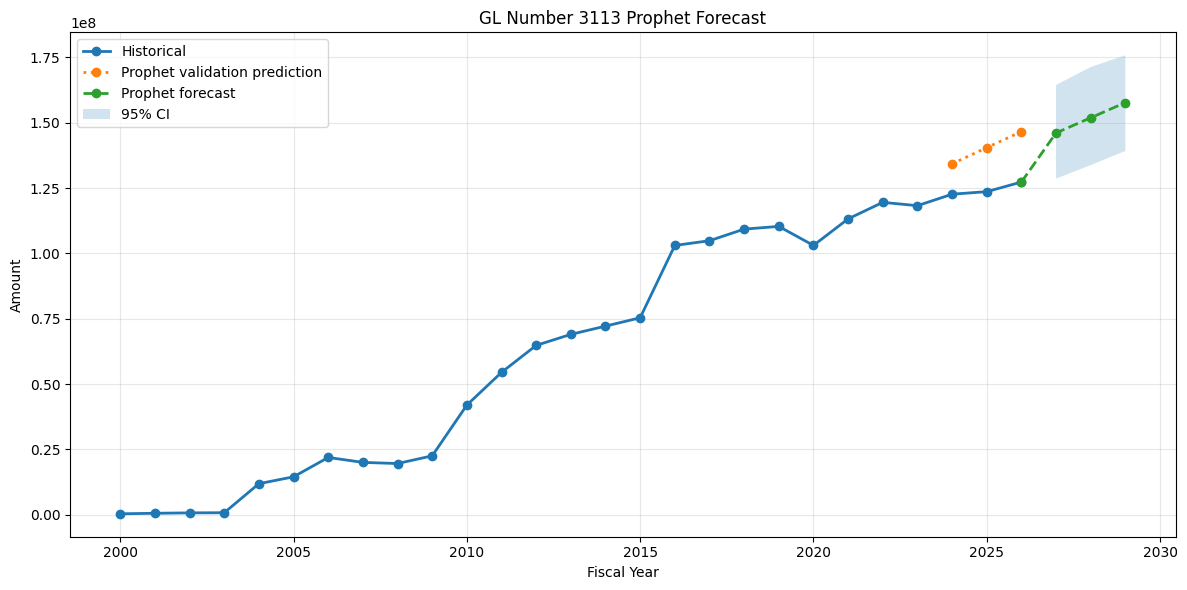

In [16]:
from prophet import Prophet
import logging
import pandas as pd


logging.getLogger("cmdstanpy").setLevel(logging.WARNING)
logging.getLogger("prophet").setLevel(logging.WARNING)


# Prepare annual GL 3113 series for Prophet.
# Prophet requires columns named ds and y. Each FY is represented as Jan 1 of that FY.
prophet_series = [
    (int(row["fy"]), row["total_amount"])
    for row in gl_3113_fy_series
    if str(row.get("fy", "")).strip().isdigit()
]
prophet_series = sorted(prophet_series, key=lambda item: item[0])

prophet_years = [item[0] for item in prophet_series]
prophet_amounts = [item[1] for item in prophet_series]

prophet_df = pd.DataFrame({
    "ds": pd.to_datetime([f"{year}-01-01" for year in prophet_years]),
    "y": prophet_amounts,
    "fy": prophet_years,
})


def fit_prophet_forecast(train_df, forecast_years):
    model = Prophet(
        yearly_seasonality=False,
        weekly_seasonality=False,
        daily_seasonality=False,
        seasonality_mode="additive",
        changepoint_prior_scale=0.05,
        interval_width=0.95,
    )
    model.fit(train_df[["ds", "y"]])

    future_df = pd.DataFrame({
        "ds": pd.to_datetime([f"{year}-01-01" for year in forecast_years]),
        "fy": forecast_years,
    })
    forecast = model.predict(future_df)
    forecast["fy"] = forecast_years
    return model, forecast


# Validation report: train through all but the last 3 FYs, then validate on the last 3 FYs.
prophet_holdout_size = 3
prophet_train_df = prophet_df.iloc[:-prophet_holdout_size].copy()
prophet_test_df = prophet_df.iloc[-prophet_holdout_size:].copy()
prophet_test_years = prophet_test_df["fy"].tolist()
prophet_test_actual = prophet_test_df["y"].tolist()

prophet_validation_model, prophet_validation_forecast = fit_prophet_forecast(
    prophet_train_df,
    prophet_test_years,
)
prophet_test_predicted = prophet_validation_forecast["yhat"].tolist()

prophet_validation_metrics = {
    "model": "Prophet trend model",
    "validation_mae": mean_absolute_error(prophet_test_actual, prophet_test_predicted),
    "validation_mape": mean_absolute_percentage_error(prophet_test_actual, prophet_test_predicted),
}

try:
    prophet_validation_report = sorted(
        [*model_comparison, prophet_validation_metrics],
        key=lambda row: row["validation_mae"],
    )
except NameError:
    prophet_validation_report = [prophet_validation_metrics]


# Fit Prophet on all historical data and predict the next 3 fiscal years.
prophet_future_years = [prophet_years[-1] + i for i in range(1, 4)]
prophet_final_model, prophet_final_forecast = fit_prophet_forecast(
    prophet_df,
    prophet_future_years,
)

gl_3113_prophet_forecast = [
    {
        "fy": str(int(row["fy"])),
        "predicted_amount": float(row["yhat"]),
        "lower_95_ci": float(row["yhat_lower"]),
        "upper_95_ci": float(row["yhat_upper"]),
        "method": "Prophet trend model",
    }
    for _, row in prophet_final_forecast.iterrows()
]


# Plot historical values, holdout validation prediction, and final Prophet forecast.
plt.figure(figsize=(12, 6))
plt.plot(prophet_years, prophet_amounts, marker="o", linewidth=2, label="Historical")
plt.plot(
    prophet_test_years,
    prophet_test_predicted,
    marker="o",
    linestyle=":",
    linewidth=2,
    label="Prophet validation prediction",
)
plt.plot(
    [prophet_years[-1], *prophet_future_years],
    [prophet_amounts[-1], *prophet_final_forecast["yhat"].tolist()],
    marker="o",
    linestyle="--",
    linewidth=2,
    label="Prophet forecast",
)
plt.fill_between(
    prophet_future_years,
    prophet_final_forecast["yhat_lower"],
    prophet_final_forecast["yhat_upper"],
    alpha=0.2,
    label="95% CI",
)
plt.title("GL Number 3113 Prophet Forecast")
plt.xlabel("Fiscal Year")
plt.ylabel("Amount")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# Validation report and final forecast table.
validation_rows = "".join(
    f"<tr><td>{escape(row['model'])}</td><td>{money(row['validation_mae'])}</td><td>{pct(row['validation_mape'])}</td></tr>"
    for row in prophet_validation_report
)
prophet_forecast_rows = "".join(
    f"<tr><td>{row['fy']}</td><td>{money(row['predicted_amount'])}</td><td>{money(row['lower_95_ci'])}</td><td>{money(row['upper_95_ci'])}</td><td>{escape(row['method'])}</td></tr>"
    for row in gl_3113_prophet_forecast
)

prophet_report_html = f"""
    <h3>Validation Report Including Prophet</h3>
    <table>
        <thead><tr><th>Model</th><th>Validation MAE</th><th>Validation MAPE</th></tr></thead>
        <tbody>{validation_rows}</tbody>
    </table>
    <h3>Prophet 3-Year Forecast</h3>
    <table>
        <thead><tr><th>FY</th><th>Predicted Amount</th><th>Lower 95% CI</th><th>Upper 95% CI</th><th>Method</th></tr></thead>
        <tbody>{prophet_forecast_rows}</tbody>
    </table>
"""

display(HTML(prophet_report_html) if HTML else {"validation": prophet_validation_report, "forecast": gl_3113_prophet_forecast})

# Sectoral

In [7]:
import pandas as pd

# Load the CSV file into a pandas DataFrame
df_all = pd.read_csv(csv_path)

In [10]:
# Get a list of all unique GL Numbers to iterate through
# Exclude GL Number 3113 as it has already been analyzed
all_gl_numbers = df_all['GL Number'].unique()
# filtered_gl_numbers = [gl for gl in all_gl_numbers if gl != 3113]

filtered_gl_numbers = [3113, 3052, 3130, 3066, 3050, 3073, 3053, 3152, 3101, 3004, 3005, 3114, 3002, 3047, 3044, 3043, 3003, 3042, 3276, 3075]
# For demonstration, let's pick the first GL number from the filtered list
current_gl_number = filtered_gl_numbers[0]

print(f"Starting analysis for GL Number: {current_gl_number}")

Starting analysis for GL Number: 3113


## GL - 3052 Cigerate Tax

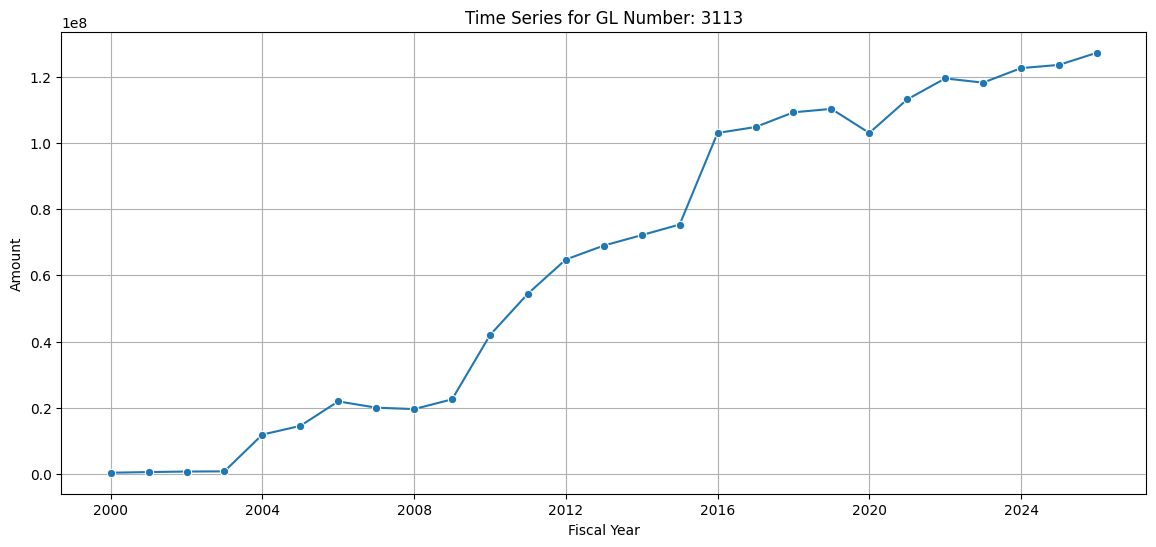

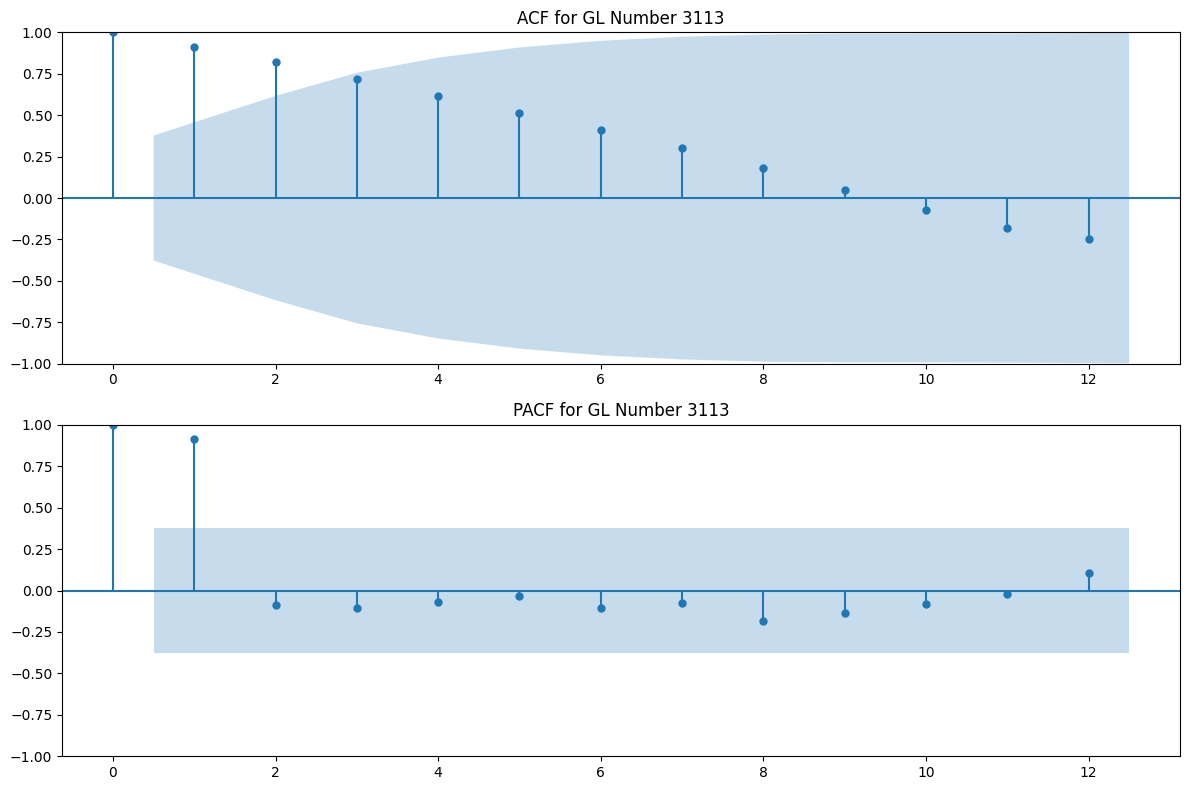


Unit Root Tests for GL Number 3113:

--- Original Series (Level) ---
Augmented Dickey-Fuller Test for Original Series (Level):
  ADF Statistic: -1.5192
  p-value: 0.5240
  Critical Values:
    1%: -3.8092
    5%: -3.0216
    10%: -2.6507
KPSS Test for Original Series (Level):
  KPSS Statistic: 0.7576
  p-value: 0.0100
  Critical Values:
    10%: 0.3470
    5%: 0.4630
    2.5%: 0.5740
    1%: 0.7390

--- First-Differenced Series ---
Augmented Dickey-Fuller Test for First-Differenced Series:
  ADF Statistic: -2.9748
  p-value: 0.0373
  Critical Values:
    1%: -3.8893
    5%: -3.0544
    10%: -2.6670
KPSS Test for First-Differenced Series:
  KPSS Statistic: 0.1169
  p-value: 0.1000
  Critical Values:
    10%: 0.3470
    5%: 0.4630
    2.5%: 0.5740
    1%: 0.7390

Based on ACF/PACF plots and unit root tests for GL Number 3113:

Assuming d=1 if non-stationary (first difference makes it stationary), p=1 based on PACF, q=0 based on ACF as a starting point. 
Optimal orders may vary per serie

c:\Users\Syed.Uddin\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)
c:\Users\Syed.Uddin\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)
c:\Users\Syed.Uddin\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)
c:\Users\Syed.Uddin\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\statespace\representation.py:374: FutureWarning: Unknown keyword arguments: dict_keys(['typ']).Passing unknown keyword arguments will raise a TypeError beginning in versio

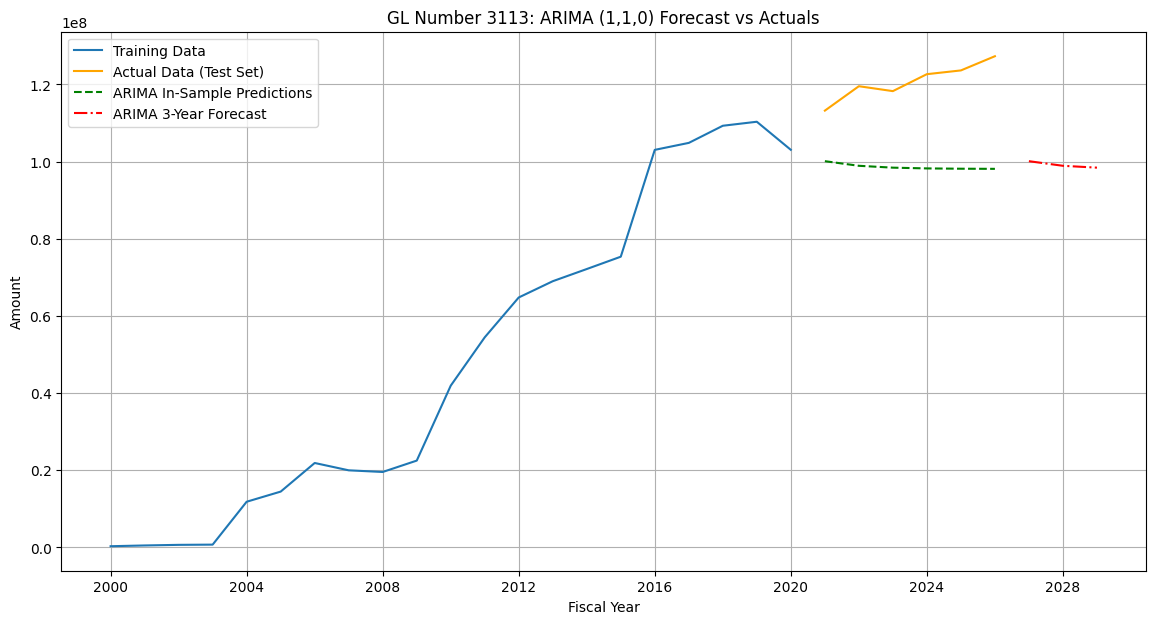

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error
import numpy as np
import pandas as pd

if current_gl_number is not None:
    # Filter data for the current GL Number and aggregate by fiscal year
    gl_data_series = df_all[df_all['GL Number'] == current_gl_number].groupby('fy')['Amount'].sum()

    # Convert to a Series with 'fy' as datetime index for time series analysis
    gl_series = pd.Series(gl_data_series.values, index=pd.to_datetime(gl_data_series.index, format='%Y'))

    # --- i) Plot the series over time, ACF & PACF ---
    plt.figure(figsize=(14, 6))
    sns.lineplot(x=gl_series.index, y=gl_series.values, marker='o')
    plt.title(f'Time Series for GL Number: {current_gl_number}')
    plt.xlabel('Fiscal Year')
    plt.ylabel('Amount')
    plt.grid(True)
    plt.show()

    # Determine maximum lags for ACF/PACF plots based on series length
    max_lags_plot = min(12, len(gl_series) // 2 - 1) if len(gl_series) > 2 else 1 # Ensure at least 1 lag

    fig, axes = plt.subplots(2, 1, figsize=(12, 8))
    plot_acf(gl_series, ax=axes[0], lags=max_lags_plot)
    plot_pacf(gl_series, ax=axes[1], lags=max_lags_plot)
    axes[0].set_title(f'ACF for GL Number {current_gl_number}')
    axes[1].set_title(f'PACF for GL Number {current_gl_number}')
    plt.tight_layout()
    plt.show()

    # --- ii) Unit root test for level and first-difference ---
    def conduct_unit_root_tests(series, title):
        print(f"\n--- {title} ---")
        # ADF Test
        adf_result = adfuller(series, autolag='AIC')
        print(f'Augmented Dickey-Fuller Test for {title}:')
        print(f'  ADF Statistic: {adf_result[0]:.4f}')
        print(f'  p-value: {adf_result[1]:.4f}')
        print('  Critical Values:')
        for key, value in adf_result[4].items():
            print(f'    {key}: {value:.4f}')

        # KPSS Test
        # Catch the InterpolationWarning that might occur with certain p-values
        import warnings
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", category=UserWarning)
            kpss_result = kpss(series, regression='c', nlags='auto')
        print(f'KPSS Test for {title}:')
        print(f'  KPSS Statistic: {kpss_result[0]:.4f}')
        print(f'  p-value: {kpss_result[1]:.4f}')
        print('  Critical Values:')
        for key, value in kpss_result[3].items():
            print(f'    {key}: {value:.4f}')

    # Conduct tests on the original series
    print(f"\nUnit Root Tests for GL Number {current_gl_number}:")
    conduct_unit_root_tests(gl_series, 'Original Series (Level)')

    # Conduct tests on the first-differenced series
    # Handle cases where differencing results in too few data points
    if len(gl_series) > 1:
        gl_series_diff = gl_series.diff().dropna()
        if not gl_series_diff.empty:
            conduct_unit_root_tests(gl_series_diff, 'First-Differenced Series')
        else:
            print("\nFirst-differenced series is empty, cannot perform unit root test.")
    else:
        print("\nSeries is too short to perform first-differencing.")

    # --- iii) Find the lag orders (interpretation based on plots and tests) ---
    print(f"\nBased on ACF/PACF plots and unit root tests for GL Number {current_gl_number}:\n")
    print("Assuming d=1 if non-stationary (first difference makes it stationary), p=1 based on PACF, q=0 based on ACF as a starting point. \nOptimal orders may vary per series. For automation, we will start with (1,1,0).")

    # --- iv) ARIMA regression and v) prediction for the next 3 fy ---

    # Split data into train and test sets (if enough data points exist)
    # For very short series, we might not have enough for a test set.
    if len(gl_series) >= 5: # Require at least 5 data points for a meaningful train/test split
        train_size = int(len(gl_series) * 0.8)
        train, test = gl_series[0:train_size], gl_series[train_size:]
    else:
        train = gl_series # Use all data for training if series is too short
        test = pd.Series() # Empty test set
        print("\nSeries is too short for a standard train/test split, using all data for training.")

    # Define the number of future predictions
    num_forecast_steps = 3

    try:
        # Fit ARIMA model (p=1, d=1, q=0) - using d=1 to ensure stationarity
        # Note: The order (1,1,0) is a starting point, and might not be optimal for all series.
        model = ARIMA(train, order=(1, 1, 0))
        model_fit = model.fit()

        print(f"\nARIMA Model Summary for GL Number {current_gl_number}:")
        print(model_fit.summary())

        # Make predictions (in-sample for test set and out-of-sample for future)
        if not test.empty:
            # Predictions for the test set
            start_index_test = len(train)
            end_index_test = len(gl_series) - 1
            predictions_test = model_fit.predict(start=start_index_test, end=end_index_test, typ='levels')
            rmse = np.sqrt(mean_squared_error(test, predictions_test))
            print(f"\nRoot Mean Squared Error (RMSE) on Test Set: {rmse:.2f}")
        else:
            predictions_test = pd.Series() # Empty series if no test set
            print("\nNo test set available for RMSE calculation.")

        # Forecast for the next `num_forecast_steps` fiscal years
        forecast_index = pd.date_range(start=gl_series.index[-1] + pd.DateOffset(years=1), periods=num_forecast_steps, freq='YS')
        forecast_result = model_fit.get_forecast(steps=num_forecast_steps)
        forecast = forecast_result.predicted_mean
        forecast.index = forecast_index
        print(f"\nForecast for the next {num_forecast_steps} fiscal years:\n{forecast}")

        # Plot predictions vs actuals, and future forecast
        plt.figure(figsize=(14, 7))
        plt.plot(train.index, train, label='Training Data')
        if not test.empty:
            plt.plot(test.index, test, label='Actual Data (Test Set)', color='orange')
            plt.plot(predictions_test.index, predictions_test, label='ARIMA In-Sample Predictions', color='green', linestyle='--')
        plt.plot(forecast.index, forecast, label=f'ARIMA {num_forecast_steps}-Year Forecast', color='red', linestyle='-.')
        plt.title(f'GL Number {current_gl_number}: ARIMA (1,1,0) Forecast vs Actuals')
        plt.xlabel('Fiscal Year')
        plt.ylabel('Amount')
        plt.legend()
        plt.grid(True)
        plt.show()

    except ValueError as e:
        print(f"\nCould not fit ARIMA model for GL Number {current_gl_number}: {e}")
        print("This might happen for very short or constant series.")
    except Exception as e:
        print(f"\nAn unexpected error occurred during ARIMA modeling for GL Number {current_gl_number}: {e}")
else:
    print("No more GL Numbers to process.")